In [6]:
import numpy as np
import pandas as pd

from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

print("Libraries imported successfully")

Libraries imported successfully


In [7]:

# Create a sample dataset
X = np.array([
    [1, 2],
    [2, 1],
    [2, 3],
    [3, 2],
    [3, 3],

    [7, 8],
    [8, 7],
    [8, 9],
    [9, 8],
    [9, 9],

    [1, 8],
    [2, 9],
    [2, 7],
    [3, 8],
    [3, 9]
])

print("Dataset shape:", X.shape)
print("\nDataset:")
print(X)


Dataset shape: (15, 2)

Dataset:
[[1 2]
 [2 1]
 [2 3]
 [3 2]
 [3 3]
 [7 8]
 [8 7]
 [8 9]
 [9 8]
 [9 9]
 [1 8]
 [2 9]
 [2 7]
 [3 8]
 [3 9]]


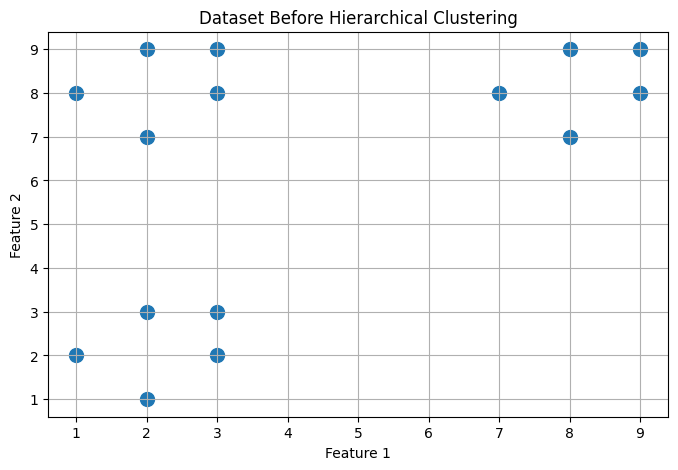

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    s=100
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Dataset Before Hierarchical Clustering")

plt.grid(True)
plt.show()

In [9]:
hc = AgglomerativeClustering(n_clusters=3)

labels = hc.fit_predict(X)

print("Labels: ",labels)

Labels:  [2 2 2 2 2 0 0 0 0 0 1 1 1 1 1]


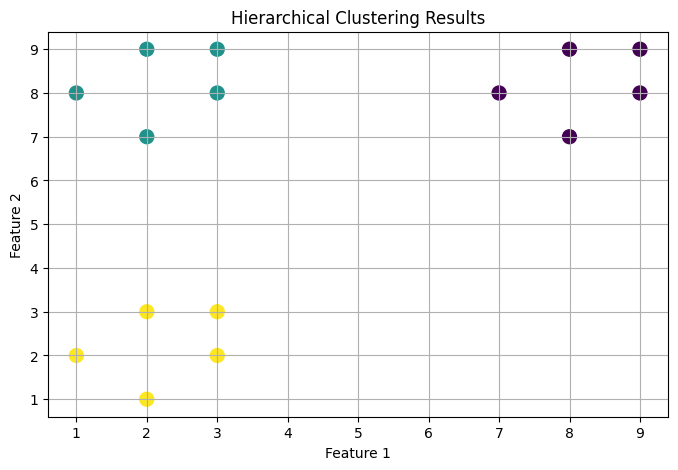

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels,
    cmap="viridis",
    s=100
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Hierarchical Clustering Results")

plt.grid(True)
plt.show()

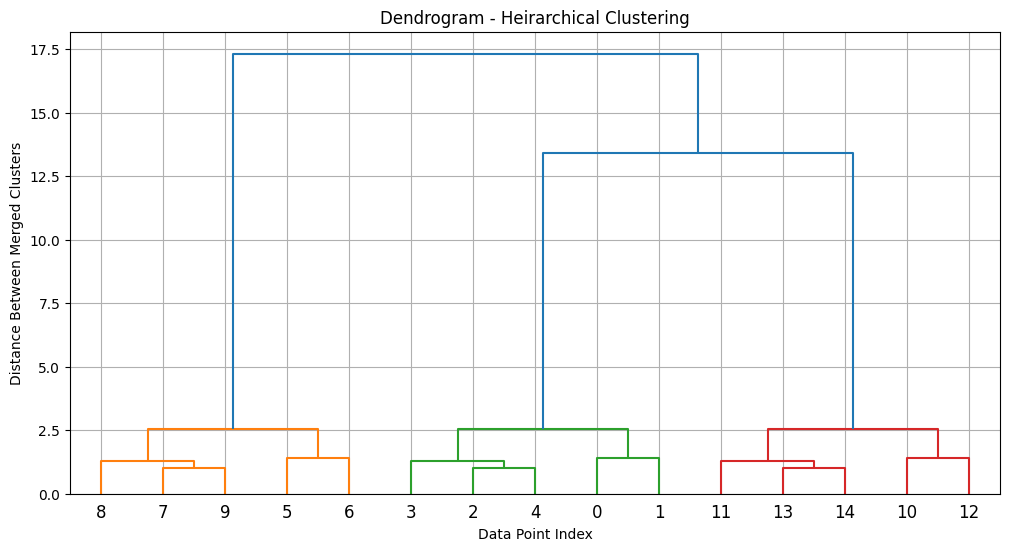

In [12]:
Z = linkage(X, method="ward")

plt.figure(figsize=(12, 6))

dendrogram(Z)

plt.title("Dendrogram - Heirarchical Clustering")
plt.xlabel("Data Point Index")
plt.ylabel("Distance Between Merged Clusters")

plt.grid(True)
plt.show()

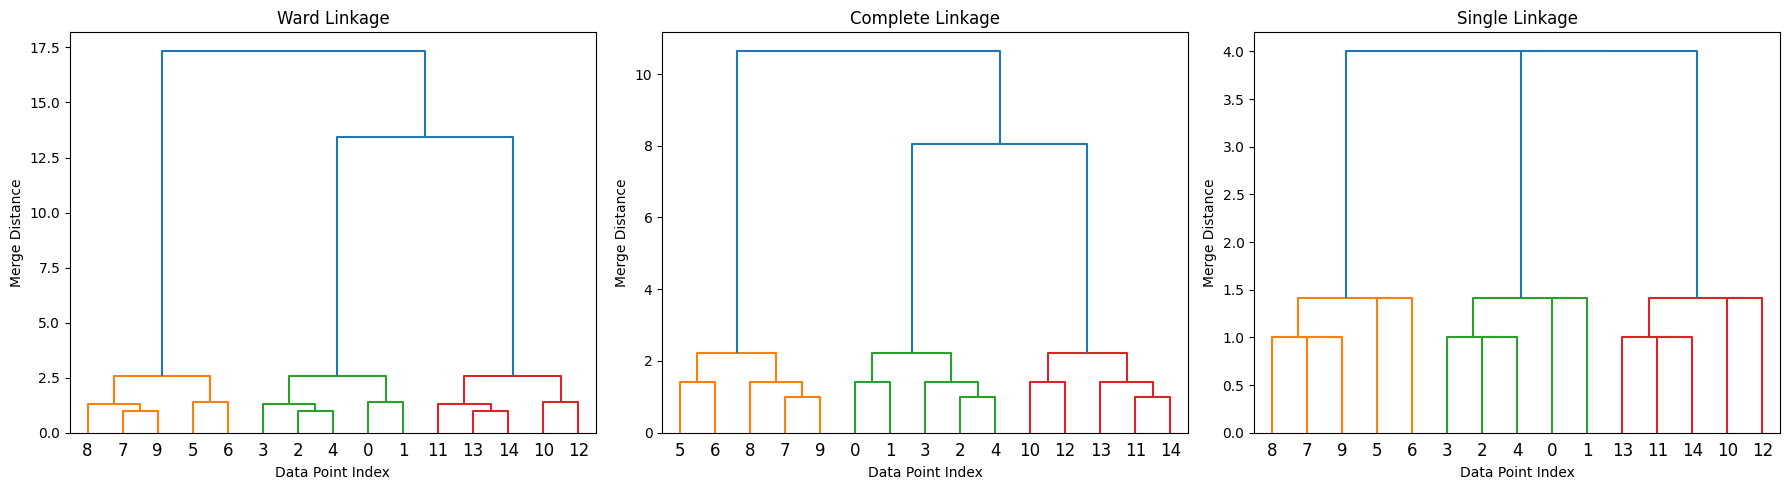

In [14]:
methods = ["ward", "complete", "single"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax,method in zip(axes, methods):
  Z_method = linkage(X, method=method)
  dendrogram(Z_method, ax=ax)

  ax.set_title(f"{method.capitalize()} Linkage")
  ax.set_xlabel("Data Point Index")
  ax.set_ylabel("Merge Distance")

plt.tight_layout()
plt.show()

In [15]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

hc = AgglomerativeClustering(n_clusters=3)
hc_labels = hc.fit_predict(X)

km = KMeans(n_clusters=3, random_state=42, n_init=10)
km_labels = km.fit_predict(X)

hc_silhouette = silhouette_score(X, hc_labels)
km_silhouette = silhouette_score(X, km_labels)

print("Hierarchical Silhouette Clustering Score: ",hc_silhouette)
print("K-Means Silhouette Clustering Score: ",km_silhouette)

Hierarchical Silhouette Clustering Score:  0.7226974693707949
K-Means Silhouette Clustering Score:  0.7226974693707949
